# ms-eCPA parametrization: interactive tutorial

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmoortgat/CPA_and_eCPA_flash/blob/main/notebooks/ms_ecpa_parametrization_tutorial.ipynb)

This notebook is a hands-on guide to the ion-specific electrolyte Cubic-Plus-Association
equation of state **ms-eCPA** of Paper II:

J. Moortgat, F. Mourão Coelho, A. Firoozabadi. Phase Equilibria of CO$_2$ and CH$_4$ in
Multisalt Brines: Parametrization and Validation of an Ion-Specific Electrolyte
Cubic-Plus-Association Equation of State. *Energy & Fuels* **2026**, 40, 23472–23484.
[doi:10.1021/acs.energyfuels.6c04568](https://doi.org/10.1021/acs.energyfuels.6c04568)

ms-eCPA describes water, CO$_2$, CH$_4$ and the ions Na$^+$, K$^+$, Ca$^{2+}$, Mg$^{2+}$,
Cl$^-$ and SO$_4^{2-}$. The model is the `ms_ecpa` package in the `multisalt/` folder of
this repository. Each section below makes a few direct calls to that package and plots
the result. All cells run live, on your machine or on Google Colab. Change a temperature,
a pressure or a brine composition and run the cell again.

The executable paper
[`ms_ecpa_parametrization_paper.ipynb`](ms_ecpa_parametrization_paper.ipynb) reproduces
every figure and table of Paper II with purpose-built scripts. This tutorial shows the
calls that those scripts make.

**Contents**

1. [Getting started](#sec1)
2. [Conventions and the parameter set](#sec2)
3. [Brine density](#sec3)
4. [Water activity and osmotic coefficient](#sec4)
5. [Gas solubility in water and single-salt brines](#sec5)
6. [Mixed-salt brines](#sec6)
7. [Water content of the CO$_2$-rich phase](#sec7)
8. [Enthalpy of CO$_2$ dissolution](#sec8)
9. [Going further](#sec9)

<a id="sec1"></a>
## 1. Getting started

The cell below prepares the environment. On Colab it clones the repository and installs
CoolProp. It then moves into the `multisalt/` folder and puts that folder and
`multisalt/scripts/` on the Python path. No installation of the package is needed.

The package has two implementations of the same kernel: Python, and an optional compiled
Fortran library (`make -C fortran` builds it). The cell selects the Fortran library when
it has been built. The two give the same numbers; the Fortran library is about 190 times
faster for the stability-and-flash call. With the Python kernel, which is what Colab uses,
the whole notebook runs in about two minutes.

In [1]:
# Setup: run this cell first (locally or on Google Colab).
import os, sys, subprocess

if "google.colab" in sys.modules and not os.path.exists("CPA_and_eCPA_flash"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/jmoortgat/CPA_and_eCPA_flash.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "CoolProp"], check=True)

# work from the multisalt/ directory of the repository
for cand in ("CPA_and_eCPA_flash/multisalt", "../multisalt", "multisalt", "."):
    if os.path.exists(os.path.join(cand, "ms_ecpa", "parameters.py")):
        os.chdir(cand)
        break
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "scripts")]

# use the compiled Fortran library when it has been built (make -C fortran)
built = os.listdir("fortran/build") if os.path.isdir("fortran/build") else []
if any(f.startswith("libecpa") for f in built):
    os.environ.setdefault("MS_ECPA_BACKEND", "fortran")

from ms_ecpa import backend
print("working directory:", os.path.basename(os.getcwd()) + "/",
      "| backend:", backend.mode())

working directory: multisalt/ | backend: fortran


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Figure style: bold, large text, thick black frame, no titles.
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 16, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12, "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.linewidth": 1.6, "axes.edgecolor": "black", "xtick.major.width": 1.6, "ytick.major.width": 1.6, "xtick.major.size": 6, "ytick.major.size": 6, "xtick.color": "black", "ytick.color": "black", "xtick.direction": "in", "ytick.direction": "in", "lines.linewidth": 2.2, "lines.markersize": 7, "legend.frameon": True, "legend.edgecolor": "black"})
WONG = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
LINESTYLES = ["-", "--", "-.", ":", (0, (3, 1, 1, 1, 1, 1))]
MARKERS = ["o", "s", "^", "D", "v", "P"]

# The package entry points used in this tutorial
from ms_ecpa import stability_flash, solve_elv, lnphi_aq, lnphi_gas
import ms_ecpa.parameters as prm
from ms_ecpa.parameters import Mw          # water molar mass [kg/mol]

# GasBrineBench measurements, through the loader the figure scripts use
from data_loader import load_experimental

T_START = time.perf_counter()
print("imports OK")

imports OK


<a id="sec2"></a>
## 2. Conventions and the parameter set

### 2.1 Units and composition vectors

All functions of the package use the same conventions.

- Temperature `T` in K.
- Pressure `P` in **bar** for `stability_flash`, `flash_kv` and `solve_elv`, and in
  **Pa** for the fugacity-coefficient kernels `lnphi_aq` and `lnphi_gas`.
- Ion molalities `mi`: six numbers in mol per kg of water, always in the order
  (Na$^+$, Cl$^-$, K$^+$, Ca$^{2+}$, Mg$^{2+}$, SO$_4^{2-}$). The brine must be
  electrically neutral.
- Feed `z`: mole fractions of the three species that can enter both phases,
  (H$_2$O, CH$_4$, CO$_2$), summing to 1. Ions are not part of `z`.
- Aqueous composition `x_aq = (x_H2O, x_CH4, x_CO2)` is on the total-mole basis: the
  ions are counted in the mole total. The ion mole fractions are $x_i = M_w x_{\mathrm{H_2O}} m_i$,
  so that $x_{\mathrm{H_2O}} + x_{\mathrm{CH_4}} + x_{\mathrm{CO_2}} + \sum_i x_i = 1$.
- Gas molality in the brine follows as $m_{\mathrm{CO_2}} = x_{\mathrm{CO_2}} / (M_w x_{\mathrm{H_2O}})$, in mol per kg of water.
- Salinity: by default (`salinity_convention="as-aqueous"`) `mi` is the molality of the
  aqueous phase at equilibrium, set equal to the molality of the brine as prepared.
  Section 2.6 of Paper II explains why this matches how the experiments are reported.

The small helper below builds `mi` from named ion molalities and checks neutrality.
`SALTS` holds the ion molalities of 1 mol/kg of each single salt, so that
`3 * SALTS["CaCl2"]` is a 3 mol/kg CaCl$_2$ brine.

In [3]:
ION_NAMES = ["Na+", "Cl-", "K+", "Ca2+", "Mg2+", "SO4 2-"]
ZI = np.array([1, -1, 1, 2, 2, -2])          # ion charges, same order

def brine(Na=0.0, Cl=0.0, K=0.0, Ca=0.0, Mg=0.0, SO4=0.0):
    # Ion molality vector mi [mol/kg water] in the package order.
    mi = np.array([Na, Cl, K, Ca, Mg, SO4], dtype=float)
    if abs(mi @ ZI) > 1e-6:
        raise ValueError("brine is not electrically neutral: sum(m_i z_i) = %.3g" % (mi @ ZI))
    return mi

def ionic_strength(mi):
    return 0.5 * float(np.sum(mi * ZI**2))

SALTS = {"NaCl": brine(Na=1, Cl=1), "KCl": brine(K=1, Cl=1), "CaCl2": brine(Ca=1, Cl=2),
         "MgCl2": brine(Mg=1, Cl=2), "Na2SO4": brine(Na=2, SO4=1)}
WATER = np.zeros(6)

print("3 mol/kg CaCl2:", 3 * SALTS["CaCl2"], " ionic strength:", ionic_strength(3 * SALTS["CaCl2"]), "mol/kg")

3 mol/kg CaCl2: [0. 6. 0. 3. 0. 0.]  ionic strength: 9.0 mol/kg


### 2.2 The parameter set

All parameters are module-level values in `ms_ecpa/parameters.py`. Section 2.4 of Paper II
and Section S1 of its Supporting Information describe them in three levels.

1. Pure components: SRK constants of H$_2$O, CO$_2$ and CH$_4$, and the association
   parameters of water (Table 1 of Paper II).
2. Water and gases: the gas–water binary interaction parameters $k_{ij}(T)$ of Eq. (19)
   and the CO$_2$–H$_2$O cross-association ratio (Table 2).
3. Ions: per ion a hard-sphere diameter $\sigma_i$, a Born radius $R_{B,i}$, an energy
   $a_{0,i}$, a polarizability, a water–ion interaction energy $\Delta U_{wi}(T)$
   (Eq. S15), gas–ion interaction energies $\Delta U_{ci}(T)$ and $\Delta U_{hi}(T)$
   (Eq. S16), and a Péneloux volume shift $\Upsilon_i(T)$ (Eq. 18).

The temperature dependences, in the form the code evaluates them:

$$\Delta U_{wi}(T) = \Delta U^\text{ref}_{wi} + \alpha_{wi} R \left[ \left(1-T/T^\alpha_{wi}\right)^2 - \left(1-T^\text{ref}/T^\alpha_{wi}\right)^2 \right], \qquad T^\text{ref} = 298.15 \text{ K}$$

$$\Delta U_{ci}(T) = A^{\Delta U}_{ci} T/T_{c,\mathrm{CO_2}} + B^{\Delta U}_{ci}, \qquad \Delta U_{hi}(T) = A^{\Delta U}_{hi} T/T_{c,\mathrm{CH_4}} + B^{\Delta U}_{hi}$$

$$\Upsilon_i(T) = A^\Upsilon_i T/T_{c,\mathrm{H_2O}} + B^\Upsilon_i$$

In the code the six-ion arrays are `Sgi` ($\sigma_i$, m), `Rbi` ($R_{B,i}$, m),
`Uref1i`, `Talfa1i`, `alfa1i` (water–ion), `A_U3i`, `B_U3i` (CO$_2$–ion, J/mol),
`A_U2i`, `B_U2i` (CH$_4$–ion, J/mol), and `A_Peni`, `B_Peni` (Péneloux, cm$^3$/mol).
The cell below evaluates them at one temperature.

In [4]:
def dU_water_ion(T):
    return prm.Uref1i + prm.alfa1i * prm.R * ((1 - T / prm.Talfa1i)**2 - (1 - prm.Tref / prm.Talfa1i)**2)

def dU_co2_ion(T):
    return prm.A_U3i * T / prm.Tc3 + prm.B_U3i       # J/mol

def dU_ch4_ion(T):
    return prm.A_U2i * T / prm.Tc2 + prm.B_U2i       # J/mol

def peneloux_ion(T):
    return prm.A_Peni * T / prm.Tc1 + prm.B_Peni     # cm3/mol

T = 323.15
table = pd.DataFrame({
    "z_i": prm.Zi,
    "sigma [A]": prm.Sgi * 1e10,
    "R_Born [A]": prm.Rbi * 1e10,
    "dU_wi/R [K]": dU_water_ion(T) / prm.R,
    "dU_ci/R [K]": dU_co2_ion(T) / prm.R,
    "dU_hi/R [K]": dU_ch4_ion(T) / prm.R,
    "Upsilon_i [cm3/mol]": peneloux_ion(T),
}, index=ION_NAMES)
print("Ion parameters at T = %.2f K" % T)
table.round(3)

Ion parameters at T = 323.15 K


,z_i,sigma [A],R_Born [A],dU_wi/R [K],dU_ci/R [K],dU_hi/R [K],Upsilon_i [cm3/mol]
Na+,1,2.630,1.540,144.633,1423.935,3085.144,-37.686
Cl-,-1,3.571,1.990,-267.616,658.141,461.224,-38.477
K+,1,2.900,2.040,149.067,1113.042,1656.616,-38.847
Ca2+,2,2.750,1.601,103.055,373.608,2614.395,-43.619
Mg2+,2,3.420,1.460,645.560,1385.263,2446.099,-82.437
SO4 2-,-2,3.140,2.400,-175.606,1419.475,578.580,-0.871


The gas–water binary parameters are quadratic in reduced temperature (Eq. 19 of Paper II).
The CO$_2$–ion energies are linear in $T$. The figure plots $\Delta U_{ci}/R$ for the six
ions over the CO$_2$–brine calibration range (Figure S3 of Paper II shows the same curves).

T = 298.15 K:  k_CO2-H2O = +0.0148   k_CH4-H2O = -0.0444
T = 373.15 K:  k_CO2-H2O = +0.2651   k_CH4-H2O = +0.1199
T = 473.15 K:  k_CO2-H2O = +0.5060   k_CH4-H2O = +0.1680


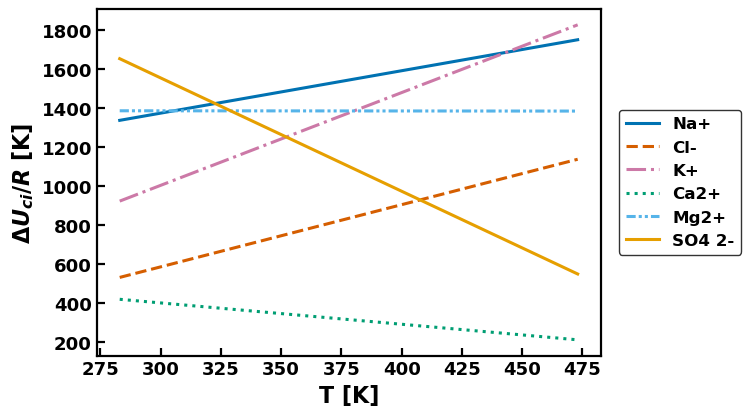

In [5]:
def k_ij(T, A, B, C, Tref):
    return A * (T / Tref)**2 + B * (T / Tref) + C

for T in (298.15, 373.15, 473.15):
    print("T = %.2f K:  k_CO2-H2O = %+.4f   k_CH4-H2O = %+.4f"
          % (T, k_ij(T, prm.Ak13, prm.Bk13, prm.Ck13, prm.Tc3),
             k_ij(T, prm.Ak12, prm.Bk12, prm.Ck12, prm.Tc1)))

T_grid = np.linspace(283.0, 473.0, 50)
dU = np.array([dU_co2_ion(T) for T in T_grid]) / prm.R
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for j, name in enumerate(ION_NAMES):
    ax.plot(T_grid, dU[:, j], color=WONG[[5, 6, 7, 3, 2, 1][j]], linestyle=LINESTYLES[j % 5], label=name)
ax.set(xlabel="T [K]", ylabel=r"$\Delta U_{ci}/R$ [K]")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Each line is one ion. These energies enter the Huron–Vidal mixing rule of the aqueous
phase (Eq. 4 of Paper II) for each CO$_2$–ion pair. Their combined effect on the CO$_2$
solubility is shown in section 5.3. The legend sits outside the axes so that it covers no
curve.

<a id="sec3"></a>
## 3. Brine density

The cubic equation of state gives the molar volume $v^\text{EoS} = Z R T / P$ of the
aqueous phase. ms-eCPA corrects it with the ion-specific Péneloux shift of Eqs. (17)
and (18) of Paper II:

$$v = v^\text{EoS} + \sum_i x_i \Upsilon_i(T), \qquad \rho = \bar{M} / v$$

with $\bar{M}$ the molar mass of the brine. The shift does not change any fugacity, so it
has no effect on phase equilibrium.

For a gas-free brine, the figure script `scripts/fig_brine_density.py` provides
`predict_rho_brine(T, P_bar, mi, v_init=None)`. It solves the aqueous-phase equations for
$Z$, the permittivity and the water association fraction, and returns
`(rho [kg/m3], state)`. Passing the returned `state` as `v_init` to the next call at a
nearby pressure speeds up the solve.

In [6]:
from fig_brine_density import predict_rho_brine

rho, state = predict_rho_brine(298.15, 100.0, 3 * SALTS["NaCl"])
Zw, eps_r, chi_w = state
print("3 mol/kg NaCl, 298.15 K, 100 bar: rho = %.2f kg/m3" % rho)
print("  Z = %.5f, relative permittivity = %.2f, water monomer fraction = %.4f" % (Zw, eps_r, chi_w))

3 mol/kg NaCl, 298.15 K, 100 bar: rho = 1106.65 kg/m3
  Z = 0.08438, relative permittivity = 58.06, water monomer fraction = 0.0883


The cell below computes NaCl brine density along three isotherms and compares it with the
densitometer data of Al Ghafri et al. in GasBrineBench (the data of Figure 1 of Paper II).
The first call to `load_experimental` locates the database, or downloads the pinned
release v1.1.1 into `~/.cache/ecpa/` (about 1.5 MB).

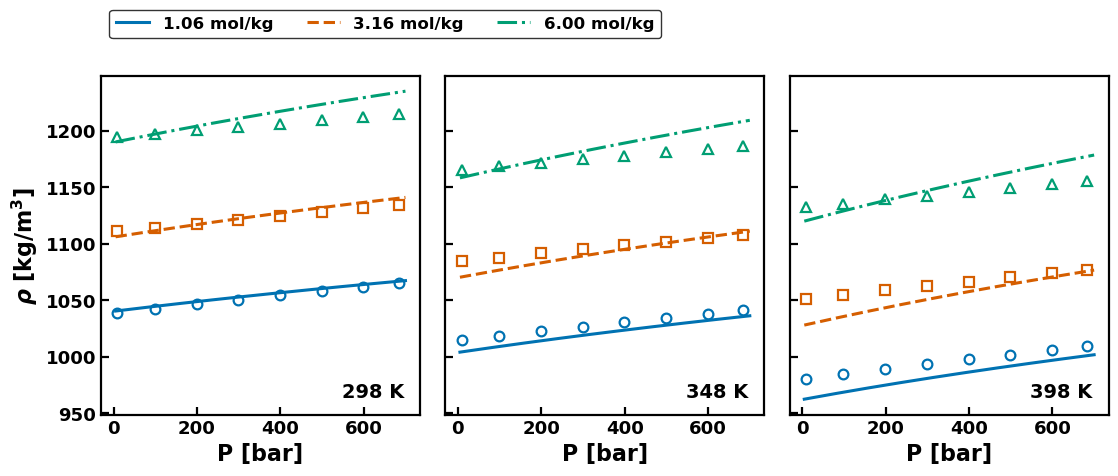

In [7]:
dens = load_experimental("brine_density")
nacl = dens[dens["salt"] == "NaCl"]
ion_cols = ["m_Na", "m_Cl", "m_K", "m_Ca", "m_Mg", "m_SO4"]

P_grid = np.linspace(5.0, 700.0, 10)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, T in zip(axes, (298.0, 348.0, 398.0)):
    for k, m in enumerate(sorted(nacl["m_salt_mol_kg"].unique())):
        mi = m * SALTS["NaCl"]
        rhos, st = [], None
        for P in P_grid:
            r, st = predict_rho_brine(T, P, mi, v_init=st)
            rhos.append(r)
        e = nacl[(nacl["T_K"] == T) & (nacl["m_salt_mol_kg"] == m)]
        ax.plot(P_grid, rhos, color=WONG[[5, 6, 3][k]], linestyle=LINESTYLES[k], label="%.2f mol/kg" % m)
        ax.plot(e["P_bar"], e["rho_exp_kg_m3"], MARKERS[k], color=WONG[[5, 6, 3][k]], mfc="none", mew=1.6, ls="none")
    ax.text(0.95, 0.05, "%.0f K" % T, transform=ax.transAxes, ha="right", fontweight="bold")
    ax.set_xlabel("P [bar]")
axes[0].set_ylabel(r"$\rho$ [kg/m$^3$]")
axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 1.22), ncol=3)
fig.subplots_adjust(wspace=0.08)
plt.show()

Lines are ms-eCPA; open symbols are the measurements. Each line is one molality, with the
same color for model and data. The density rises with salinity and falls with temperature,
and the model follows both trends. At 348 and 398 K the model lies below the 1.06 mol/kg
data, and at 6 mol/kg it rises more steeply with pressure than the data.

To score the model, evaluate it at every measured state. The loop below does this for all
189 NaCl points at 298–473 K and prints the average absolute relative deviation. It takes
about 15 s with the Python kernel.

In [8]:
t0 = time.perf_counter()
pred, st, key = [], None, None
for row in nacl.sort_values(["T_K", "m_salt_mol_kg", "P_bar"]).itertuples():
    if (row.T_K, row.m_salt_mol_kg) != key:          # new isotherm: cold start
        st, key = None, (row.T_K, row.m_salt_mol_kg)
    mi = np.array([getattr(row, c) for c in ion_cols])
    r, st = predict_rho_brine(row.T_K, row.P_bar, mi, v_init=st)
    pred.append((row.rho_exp_kg_m3, r))
pred = np.array(pred)
dev = 100 * np.abs(pred[:, 1] - pred[:, 0]) / pred[:, 0]
print("NaCl brine density: N = %d, AAD = %.2f %%, largest deviation %.1f %%  (%.1f s)"
      % (len(pred), dev.mean(), dev.max(), time.perf_counter() - t0))

NaCl brine density: N = 189, AAD = 0.99 %, largest deviation 3.5 %  (17.6 s)


Paper II reports an AAD of 0.99 % for NaCl brine density (Section 3.1). The same loop with
`dens["salt"] == "CaCl"`, `"KCl"`, `"MgCl"` or `"NaSO"` scores the other salts
(Figures S6–S9 of Paper II).

<a id="sec4"></a>
## 4. Water activity and osmotic coefficient

The osmotic coefficient of a gas-free brine follows from the water activity $a_w$:

$$\phi = -\frac{\ln a_w}{M_w \nu m}, \qquad \ln a_w = \ln x_{\mathrm{H_2O}} + \ln \hat\phi_{\mathrm{H_2O}}(\text{brine}) - \ln \phi_{\mathrm{H_2O}}(\text{pure water})$$

with $m$ the salt molality and $\nu$ the number of ions per formula unit (2 for NaCl,
3 for CaCl$_2$). Both fugacity coefficients are evaluated at the same $T$ and $P$.

`lnphi_aq(x_aq, mi, T, P)` returns the three aqueous log-fugacity coefficients
(H$_2$O, CH$_4$, CO$_2$). Here `P` is in **Pa**. `x_aq` must be on the total-mole basis
of section 2.1: for a gas-free brine $x_{\mathrm{H_2O}} = 1/(1 + M_w \sum_i m_i)$.

In [9]:
NU = {"NaCl": 2, "KCl": 2, "CaCl2": 3, "MgCl2": 3, "Na2SO4": 3}

def osmotic_coefficient(salt, m, T=298.15, P_Pa=1e5):
    mi = m * SALTS[salt]
    x_w = 1.0 / (1.0 + Mw * mi.sum())
    ln_phi_brine = lnphi_aq([x_w, 0.0, 0.0], mi, T, P_Pa)[0]
    ln_phi_pure = lnphi_aq([1.0, 0.0, 0.0], WATER, T, P_Pa)[0]
    ln_aw = np.log(x_w) + ln_phi_brine - ln_phi_pure
    return -ln_aw / (Mw * NU[salt] * m)

print("NaCl 1 mol/kg, 298.15 K, 1 bar: phi = %.4f" % osmotic_coefficient("NaCl", 1.0))
print("NaCl 0.001 mol/kg:               phi = %.4f" % osmotic_coefficient("NaCl", 0.001))

NaCl 1 mol/kg, 298.15 K, 1 bar: phi = 0.9394
NaCl 0.001 mol/kg:               phi = 0.9883


At 0.001 mol/kg the model approaches the Debye–Hückel limiting law. Paper II reports
0.9882 against the Pitzer value 0.9884 (Section 3.2).

The reference in Paper II is the Pitzer correlation with the constants of Pitzer and
Mayorga (1973), in `scripts/pitzer_constants.py`. The figure compares the two for three
salts at 298.15 K and 1 bar.

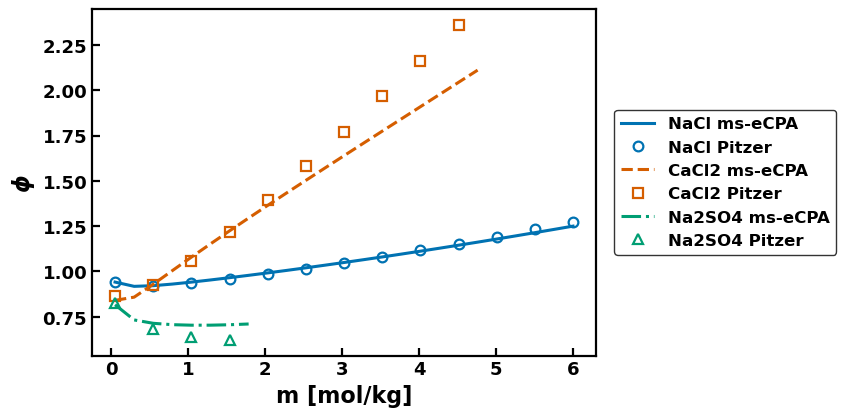

In [10]:
import pitzer_constants

m_grid = np.linspace(0.05, 6.0, 25)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, (salt, m_max) in enumerate([("NaCl", 6.0), ("CaCl2", 5.0), ("Na2SO4", 2.0)]):
    m = m_grid[m_grid <= m_max]
    c = WONG[[5, 6, 3][k]]
    ax.plot(m, [osmotic_coefficient(salt, mm) for mm in m], color=c, linestyle=LINESTYLES[k], label=salt + " ms-eCPA")
    ax.plot(m[::2], pitzer_constants.phi_osm(m[::2], salt), MARKERS[k], color=c, mfc="none", mew=1.6, ls="none", label=salt + " Pitzer")
ax.set(xlabel="m [mol/kg]", ylabel=r"$\phi$")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

The Paper II figures use `scripts/total_mole_basis.py`, a separate assembly of the same
Helmholtz-energy terms, through `phi_osm_total(salt, m, T, P_Pa)`. The table compares both
routes and the Pitzer reference over the molality range in which each salt's ion parameters
were fitted. The grid is the one of `scripts/fig_colligative.py`. The last column is
Table 3 of Paper II.

In [11]:
from total_mole_basis import phi_osm_total

# salt: (largest molality plotted in Paper II, upper end of the fit range, Paper II Table 3 [%])
RANGES = {"NaCl": (6.0, 6.0, 0.60), "KCl": (4.5, 6.0, 2.01), "CaCl2": (5.0, 2.0, 1.39),
          "MgCl2": (4.5, 2.0, 0.85), "Na2SO4": (2.0, 2.0, 8.57)}
rows = []
for salt, (m_max, m_fit, paper) in RANGES.items():
    m = np.unique(np.concatenate([np.linspace(0.05, m_max, 25), [0.5, 1.0, 2.0]]))
    m = m[m <= min(m_fit, m_max) + 1e-12]
    ref = pitzer_constants.phi_osm(m, salt)
    a = np.array([osmotic_coefficient(salt, mm) for mm in m])
    b = np.array([phi_osm_total(salt, mm) for mm in m])
    rows.append({"salt": salt, "m range": "0.05-%g" % min(m_fit, m_max),
                 "RAD lnphi_aq [%]": 100 * np.mean(np.abs(a - ref) / ref),
                 "RAD phi_osm_total [%]": 100 * np.mean(np.abs(b - ref) / ref),
                 "Paper II [%]": paper})
pd.DataFrame(rows).set_index("salt").round(2)

,m range,RAD lnphi_aq [%],RAD phi_osm_total [%],Paper II [%]
salt,,,,
NaCl,0.05-6,0.59,0.60,0.60
KCl,0.05-4.5,2.03,2.01,2.01
CaCl2,0.05-2,1.39,1.39,1.39
MgCl2,0.05-2,0.87,0.85,0.85
Na2SO4,0.05-2,8.57,8.57,8.57


The two routes agree to within about 0.05 % in $\phi$, and `phi_osm_total` reproduces
Table 3 of Paper II. Pitzer and Mayorga anchored their constants to data up to 6 mol/kg for
NaCl, 2.5 for CaCl$_2$ and 4 for Na$_2$SO$_4$; beyond those molalities the Pitzer values in the
figure are extrapolations. Above 2 mol/kg for CaCl$_2$, MgCl$_2$ and Na$_2$SO$_4$ the ion parameters
are not constrained by colligative data; Paper II recommends $m \le 2$ mol/kg there for the
best accuracy.

<a id="sec5"></a>
## 5. Gas solubility in water and single-salt brines

### 5.1 One stability-and-flash call

`stability_flash(T, P, z, mi)` is the equilibrium calculation behind the solubility results
of Paper II (Section 2.6). It first runs a Michelsen tangent-plane-distance stability test.
If the feed is unstable, it runs a two-phase $K$-value flash. Arguments: `T` in K, `P` in
bar, `z` the feed of (H$_2$O, CH$_4$, CO$_2$), `mi` the ion molalities. Paper III
describes the algorithm.

Here: 10 mol % CO$_2$ and 90 mol % water, in 1 mol/kg NaCl at 323.15 K and 100 bar.

In [12]:
mi = 1.0 * SALTS["NaCl"]
r = stability_flash(323.15, 100.0, np.array([0.90, 0.0, 0.10]), mi)
f = r.flash_result
print("phases     :", r.phases, "|", r.message)
print("tpd_min    : %.4f   (negative: the single phase is unstable)" % r.tpd_min)
print("x_aq       : H2O %.5f  CH4 %.1e  CO2 %.5f   (total-mole basis)" % f.x_aq)
print("y_gas      : H2O %.5f  CH4 %.1e  CO2 %.5f" % f.y_gas)
print("beta       : %.4f   (mole fraction of the gas phase, ions excluded)" % f.beta)
print("Z_aq, Z_gas: %.4f, %.4f    eps_r (aqueous): %.2f" % (f.Z_aq, f.Z_gas, f.eps_r))
print("converged  :", f.converged, "| SSI + Newton iterations:", f.n_iter_ssi, "+", f.n_iter_newton)
x_w, x_h, x_c = f.x_aq
print("ions       : %.5f   (1 - sum of x_aq = Mw * x_H2O * sum(mi) = %.5f)" % (1 - sum(f.x_aq), Mw * x_w * mi.sum()))
print("CO2 molality: %.4f mol/kg water" % (x_c / (Mw * x_w)))

phases     : 2 | two-phase (trial K-init)
tpd_min    : -1.4233   (negative: the single phase is unstable)
x_aq       : H2O 0.94916  CH4 0.0e+00  CO2 0.01664   (total-mole basis)
y_gas      : H2O 0.00273  CH4 0.0e+00  CO2 0.99727
beta       : 0.0845   (mole fraction of the gas phase, ions excluded)
Z_aq, Z_gas: 0.0729, 0.4420    eps_r (aqueous): 59.97
converged  : True | SSI + Newton iterations: 5 + 1
ions       : 0.03420   (1 - sum of x_aq = Mw * x_H2O * sum(mi) = 0.03420)
CO2 molality: 0.9730 mol/kg water


The result has the fields of `StabilityFlashResult`; `r.flash_result` holds the flash
(`FlashKVResult`) and is `None` when the feed is a single phase. The three aqueous fractions
do not sum to 1, because the ions take the rest: the printed ion mole fraction equals
$M_w x_{\mathrm{H_2O}} \sum_i m_i$.

### 5.2 Solubility isotherms

In the two-phase region the phase compositions at fixed $T$, $P$ and `mi` do not depend on
the feed. A feed can still fail to split, for example when all of its gas dissolves. The
figure scripts therefore try a short list of feeds and accept the first converged two-phase
result. They also reject a result whose aqueous phase has the feed composition, because no
gas has then moved between the phases. The helper below does the same.

In [13]:
Z_GAS_TRIES = (0.05, 0.10, 0.02, 0.20, 0.30)       # gas mole fraction of the feed

def gas_solubility(T, P, mi, gas="CO2"):
    # Returns (gas molality in the brine [mol/kg water], H2O mole fraction in the gas phase).
    for zg in Z_GAS_TRIES:
        z = np.array([1 - zg, zg, 0.0]) if gas == "CH4" else np.array([1 - zg, 0.0, zg])
        r = stability_flash(T, P, z, mi)
        f = r.flash_result
        if r.phases != 2 or f is None or not f.converged:
            continue
        x_w, x_h, x_c = f.x_aq
        x_g = x_h if gas == "CH4" else x_c
        if abs(x_g / (x_w + x_g) - zg) < 1e-3 * zg:   # aqueous phase = feed: no real split
            continue
        return x_g / (Mw * x_w), f.y_gas[0]
    return np.nan, np.nan

def to_molality(x_saltfree):
    # salt-free gas mole fraction x_g/(x_g + x_w) -> molality [mol/kg water]
    return x_saltfree / (1 - x_saltfree) / Mw

print("CO2 in 3 mol/kg NaCl, 323 K, 200 bar: m = %.4f mol/kg, y_H2O = %.5f" % gas_solubility(323.0, 200.0, 3 * SALTS["NaCl"]))

CO2 in 3 mol/kg NaCl, 323 K, 200 bar: m = 0.7851 mol/kg, y_H2O = 0.00447


GasBrineBench reports gas solubility in brine as the salt-free mole fraction
$x_g / (x_g + x_{\mathrm{H_2O}})$ (column `xc_W`). `to_molality` converts it to molality.
The cell below computes CO$_2$ isotherms at 323 K in water and in 1 and 3 mol/kg NaCl, and
overlays the measurements at the same temperature and molality (as in Figure 4a of Paper II).

m = 0 mol/kg: 13 pressures in 0.0 s
m = 1 mol/kg: 13 pressures in 0.0 s
m = 3 mol/kg: 13 pressures in 0.0 s


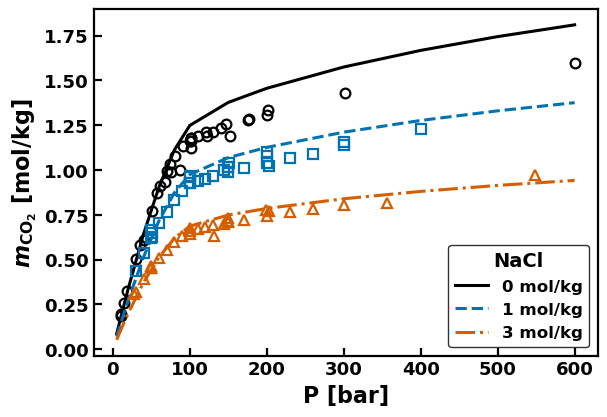

In [14]:
co2_brine = load_experimental("co2_brines")
co2_water = load_experimental("binaries_co2_water")

T = 323.0
P_grid = np.array([5, 10, 20, 40, 60, 80, 100, 150, 200, 300, 400, 500, 600.0])
iso = {}                                   # kept for section 7
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, m in enumerate([0.0, 1.0, 3.0]):
    t0 = time.perf_counter()
    iso[m] = np.array([gas_solubility(T, P, m * SALTS["NaCl"]) for P in P_grid])
    print("m = %.0f mol/kg: %d pressures in %.1f s" % (m, len(P_grid), time.perf_counter() - t0))
    c = WONG[[0, 5, 6][k]]
    ax.plot(P_grid, iso[m][:, 0], color=c, linestyle=LINESTYLES[k], label="%.0f mol/kg" % m)
    if m == 0.0:
        e = co2_water[(co2_water["T_K"].round() == T) & (co2_water["P_bar"] <= 600)].dropna(subset=["x_CO2_aq_exp"])
        m_exp = to_molality(e["x_CO2_aq_exp"])
    else:
        e = co2_brine[(co2_brine["salt"] == "NaCl") & (co2_brine["T_K"] == T) & np.isclose(co2_brine["ms_mol_kg"], m)]
        m_exp = to_molality(e["xc_W"])
    ax.plot(e["P_bar"], m_exp, MARKERS[k], color=c, mfc="none", mew=1.6, ls="none")
ax.set(xlabel="P [bar]", ylabel=r"$m_{\mathrm{CO_2}}$ [mol/kg]")
ax.legend(loc="lower right", title="NaCl")
plt.show()

Lines are ms-eCPA and open symbols are the measurements of several laboratories. Salt
lowers the CO$_2$ solubility at every pressure (salting out). Above about 200 bar the model
lies above most of the measurements at this temperature. Over all NaCl points of its
CO$_2$–brine set, Paper II reports an AAD of 5.4 % (Section 3.4 and Table S5).

### 5.3 Salting out by different salts

The ion-specific parameters give each salt its own effect. The cell below fixes 323.15 K
and 100 bar and computes the CO$_2$ molality in brines of the five salts up to 2 mol/kg,
divided by the value in pure water.

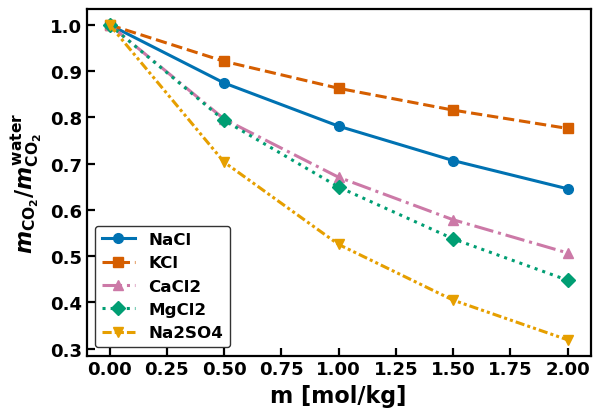

CO2 molality in pure water at 323.15 K, 100 bar: 1.2460 mol/kg


In [15]:
T, P = 323.15, 100.0
m_salt = np.array([0.5, 1.0, 1.5, 2.0])
m0 = gas_solubility(T, P, WATER)[0]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, salt in enumerate(SALTS):
    ratio = [gas_solubility(T, P, m * SALTS[salt])[0] / m0 for m in m_salt]
    ax.plot(np.r_[0.0, m_salt], np.r_[1.0, ratio], color=WONG[[5, 6, 7, 3, 1][k]], linestyle=LINESTYLES[k], marker=MARKERS[k], label=salt)
ax.set(xlabel="m [mol/kg]", ylabel=r"$m_{\mathrm{CO_2}} / m_{\mathrm{CO_2}}^{\mathrm{water}}$")
ax.legend(loc="lower left")
plt.show()
print("CO2 molality in pure water at %.2f K, %.0f bar: %.4f mol/kg" % (T, P, m0))

At equal molality, the salts with three ions per formula unit (CaCl$_2$, MgCl$_2$,
Na$_2$SO$_4$) lower the solubility more than the 1:1 salts (NaCl, KCl). The differences
between salts of the same charge type, such as KCl and NaCl, come from the ion-specific
parameters of section 2.2.

### 5.4 Methane

The same call with the gas in the CH$_4$ slot of `z` gives methane solubility. The cell
computes CH$_4$ in water and NaCl brine at 373 K up to 1400 bar and compares with the data
of Susak and McGee (brines) and the CH$_4$–H$_2$O binary set (Section 3.5 of Paper II).

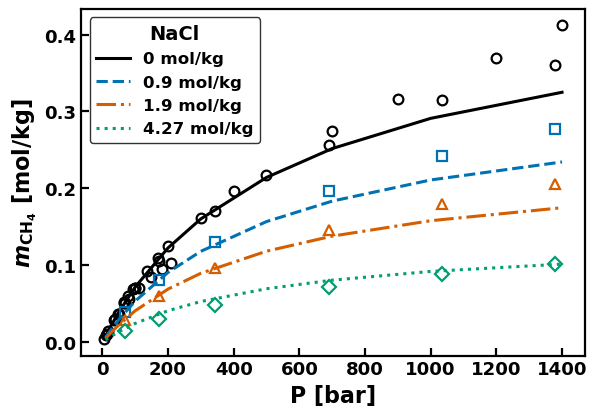

In [16]:
ch4_brine = load_experimental("ch4_brines")
ch4_water = load_experimental("binaries_ch4_water")

T = 373.0
P_grid = np.array([10, 25, 50, 100, 200, 300, 500, 700, 1000, 1400.0])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, m in enumerate([0.0, 0.9, 1.9, 4.27]):
    mh = [gas_solubility(T, P, m * SALTS["NaCl"], gas="CH4")[0] for P in P_grid]
    c = WONG[[0, 5, 6, 3][k]]
    ax.plot(P_grid, mh, color=c, linestyle=LINESTYLES[k], label="%g mol/kg" % m)
    if m == 0.0:
        e = ch4_water[(ch4_water["T_K"] == T)]
        ax.plot(e["P_bar"], to_molality(e["x_CH4_aq_exp"]), MARKERS[k], color=c, mfc="none", mew=1.6, ls="none")
    else:
        e = ch4_brine[(ch4_brine["salt"] == "NaCl") & (ch4_brine["T_K"] == T) & np.isclose(ch4_brine["ms_mol_kg"], m)]
        ax.plot(e["P_bar"], e["mh_W"], MARKERS[k], color=c, mfc="none", mew=1.6, ls="none")
ax.set(xlabel="P [bar]", ylabel=r"$m_{\mathrm{CH_4}}$ [mol/kg]")
ax.legend(loc="upper left", title="NaCl")
plt.show()

The CH$_4$ solubility keeps rising with pressure up to 1400 bar. The brine data are given as molality (column `mh_W`); the binary
data as mole fraction.

### 5.5 A second solver: `solve_elv`

`solve_elv(T, P, YC, mi)` solves the two-phase equations directly, without a stability test.
It assumes that a gas phase exists. `YC` is the water-free CO$_2$ mole fraction of the gas:
`YC=1` for CO$_2$, `YC=0` for CH$_4$. It returns an `ELVResult` with molalities (`mc`, `mh`),
the water mole fraction of the gas (`x1h`) and the density of the gas-saturated brine
(`rho_w`, with the Péneloux shift). Its range is 283 < T < 533 K and 1 < P < 1500 bar. The
CH$_4$ and binary figure scripts of Paper II use it. The table shows that both solvers give
the same answer.

In [17]:
rows = []
for gas, T, P, salt, m in [("CO2", 323.15, 200.0, "NaCl", 3.0), ("CO2", 423.15, 300.0, "CaCl2", 1.0),
                           ("CH4", 298.15, 100.0, "NaCl", 2.0), ("CH4", 423.15, 500.0, "KCl", 2.0)]:
    mi = m * SALTS[salt]
    e = solve_elv(T, P, 1.0 if gas == "CO2" else 0.0, mi)
    m_flash, y_flash = gas_solubility(T, P, mi, gas)
    rows.append({"gas": gas, "T [K]": T, "P [bar]": P, "brine": "%g m %s" % (m, salt),
                 "m stability_flash": m_flash, "m solve_elv": e.mc if gas == "CO2" else e.mh,
                 "y_H2O stability_flash": y_flash, "y_H2O solve_elv": e.x1h,
                 "rho brine [kg/m3]": e.rho_w})
pd.DataFrame(rows).round(6)

,gas,T [K],P [bar],brine,m stability_flash,m solve_elv,y_H2O stability_flash,y_H2O solve_elv,rho brine [kg/m3]
0,CO2,323.15,200.0,3 m NaCl,0.784636,0.784636,0.004500,0.004500,1097.352577
1,CO2,423.15,300.0,1 m CaCl2,0.804993,0.804993,0.058218,0.058218,1003.348162
2,CH4,298.15,100.0,2 m NaCl,0.054249,0.054249,0.000425,0.000425,1073.618584
3,CH4,423.15,500.0,2 m KCl,0.272250,0.272250,0.015504,0.015504,1014.643144


<a id="sec6"></a>
## 6. Mixed-salt brines

A mixed brine needs no extra parameters: each ion enters with its own parameters, and
ion–ion interaction energies are zero. Define the brine by its six ion molalities. The
example is brine B1 of Liu et al. (2011), with Na$^+$ 0.300, Cl$^-$ 0.851, K$^+$ 0.235 and
Ca$^{2+}$ 0.158 mol/kg (Figure 6 of Paper II). For comparison, a NaCl brine of the same
ionic strength $I = \frac{1}{2} \sum_i m_i z_i^2$ is the brine a salt-lumped model would use.

In [18]:
B1 = brine(Na=0.300, Cl=0.851, K=0.235, Ca=0.158)
I_B1 = ionic_strength(B1)
NaCl_eq = I_B1 * SALTS["NaCl"]
print("Liu 2011 B1: mi =", B1, " I = %.3f mol/kg" % I_B1)

mix = load_experimental("co2_mixed_brines")
liu = mix[np.all(np.isclose(mix[ion_cols].to_numpy(), B1, atol=5e-4), axis=1)].copy()
print(len(liu), "measurements at T =", [float(t) for t in sorted(liu["T_K"].unique())], "K")

Liu 2011 B1: mi = [0.3   0.851 0.235 0.158 0.    0.   ]  I = 1.009 mol/kg


24 measurements at T = [308.0, 318.0, 328.0] K


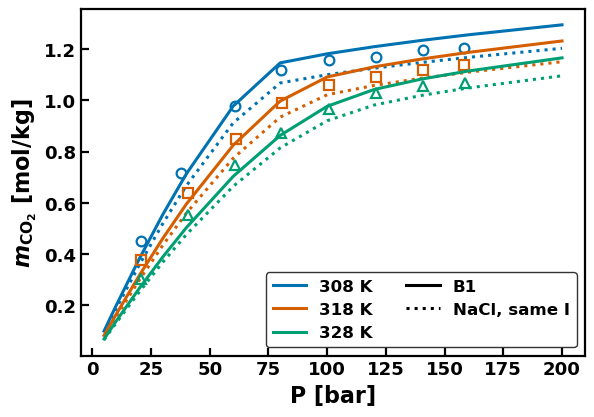

In [19]:
P_grid = np.array([5, 10, 20, 30, 40, 60, 80, 100, 120, 140, 160, 200.0])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, T in enumerate(sorted(liu["T_K"].unique())):
    c = WONG[[5, 6, 3][k]]
    ax.plot(P_grid, [gas_solubility(T, P, B1)[0] for P in P_grid], color=c, linestyle="-", label="%.0f K" % T)
    ax.plot(P_grid, [gas_solubility(T, P, NaCl_eq)[0] for P in P_grid], color=c, linestyle=":")
    e = liu[liu["T_K"] == T]
    ax.plot(e["P_bar"], to_molality(e["xc_W"]), MARKERS[k], color=c, mfc="none", mew=1.6, ls="none")
ax.plot([], [], "k-", label="B1")
ax.plot([], [], "k:", label="NaCl, same I")
ax.set(xlabel="P [bar]", ylabel=r"$m_{\mathrm{CO_2}}$ [mol/kg]")
ax.legend(loc="lower right", ncol=2)
plt.show()

Solid lines are the B1 brine, dotted lines the NaCl brine of equal ionic strength, and
symbols the data of Liu et al. Colors mark the temperature. The AAD over the measured
states quantifies the comparison:

In [20]:
liu["m_exp"] = to_molality(liu["xc_W"])
liu["m_B1"] = [gas_solubility(r.T_K, r.P_bar, B1)[0] for r in liu.itertuples()]
liu["m_NaCl_eq"] = [gas_solubility(r.T_K, r.P_bar, NaCl_eq)[0] for r in liu.itertuples()]
for col in ("m_B1", "m_NaCl_eq"):
    print("%-10s AAD = %.1f %%  (N = %d)" % (col, 100 * np.mean(np.abs(liu[col] - liu["m_exp"]) / liu["m_exp"]), len(liu)))

m_B1       AAD = 4.2 %  (N = 24)
m_NaCl_eq  AAD = 6.9 %  (N = 24)


Table S12 of Paper II reports an AAD of 4.2 % for this recipe over the same 24 points. The
ion parameters were fitted to single-salt data only, so the mixed-brine result is a
prediction (Section 3.6 of Paper II).

<a id="sec7"></a>
## 7. Water content of the CO$_2$-rich phase

The same flash also gives the composition of the gas phase. `gas_solubility` returns its
water mole fraction $y_{\mathrm{H_2O}}$ as the second value. The figure reuses the 323 K
isotherms of section 5.2 and adds the CO$_2$–H$_2$O binary data.

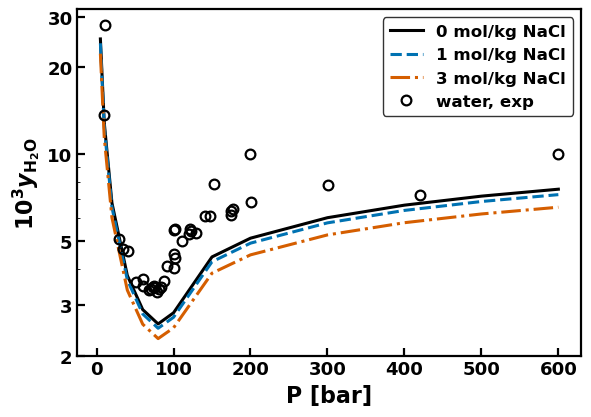

In [21]:
T = 323.0
P_grid = np.array([5, 10, 20, 40, 60, 80, 100, 150, 200, 300, 400, 500, 600.0])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, m in enumerate([0.0, 1.0, 3.0]):
    ax.plot(P_grid, 1e3 * iso[m][:, 1], color=WONG[[0, 5, 6][k]], linestyle=LINESTYLES[k], label="%.0f mol/kg NaCl" % m)
e = co2_water[(co2_water["T_K"].round() == T) & (co2_water["P_bar"] <= 600)].dropna(subset=["y_H2O_gas_exp"])
ax.plot(e["P_bar"], 1e3 * e["y_H2O_gas_exp"], "o", color=WONG[0], mfc="none", mew=1.6, ls="none", label="water, exp")
ax.set(xlabel="P [bar]", ylabel=r"$10^3 y_{\mathrm{H_2O}}$", yscale="log")
ax.set_yticks([2, 3, 5, 10, 20, 30])
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.legend(loc="upper right")
plt.show()

The water content falls with pressure to a minimum near 80 bar, where the CO$_2$-rich phase
becomes dense, and then rises again. Between 100 and 300 bar the model lies below most of
the measurements. Salt lowers the water activity
(section 4) and with it the water content of the gas. GasBrineBench holds no gas-phase
water content over brine for these conditions, so only the salt-free data are shown.

<a id="sec8"></a>
## 8. Enthalpy of CO$_2$ dissolution

Section 3.7 of Paper II tests the temperature dependence of the parameters against
flow-calorimetric enthalpies of solution of Koschel et al. (2006). In the dilute limit
(Eq. 22 of Paper II):

$$\Delta H_\text{sol} = -R T^2 \left[ \left(\partial \ln \hat\phi^\text{aq}_{\mathrm{CO_2}} / \partial T\right)_{P,x} - \left(\partial \ln \phi^\text{pure}_{\mathrm{CO_2}} / \partial T\right)_P \right]$$

The aqueous term uses `lnphi_aq` at $x_{\mathrm{CO_2}} = 10^{-4}$; the pure-gas term uses
`lnphi_gas(y, T, P)` with `y = (0, 0, 1)`. Both take `P` in Pa. The derivatives are centered
differences with $\Delta T = 0.2$ K. Here the water mole fraction includes the ions, as
section 2.1 requires.

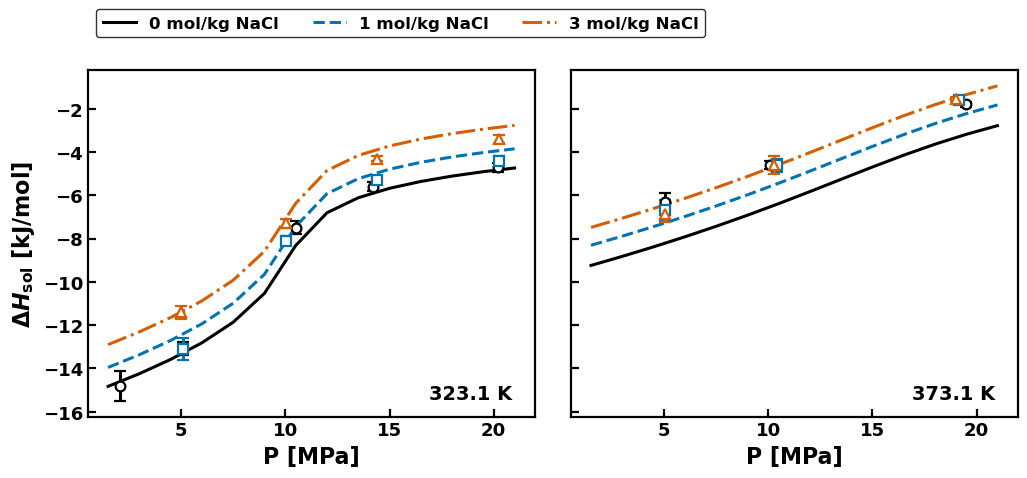

mean absolute deviation: 0.56 kJ/mol overall, 0.33 at 323.1 K, 0.88 at 373.1 K (N = 22)


In [22]:
R_GAS = 8.31446261815324     # J/(mol K)

def dH_sol(T, P_MPa, m_NaCl, x_co2=1e-4, dT=0.2):
    # Enthalpy of solution of CO2 [kJ per mol CO2] at T [K], P [MPa], NaCl molality [mol/kg].
    P = P_MPa * 1e6
    mi = m_NaCl * SALTS["NaCl"]
    x = np.array([(1 - x_co2) / (1 + Mw * mi.sum()), 0.0, x_co2])
    y = np.array([0.0, 0.0, 1.0])
    d_aq = (lnphi_aq(x, mi, T + dT, P)[2] - lnphi_aq(x, mi, T - dT, P)[2]) / (2 * dT)
    d_gas = (lnphi_gas(y, T + dT, P)[2] - lnphi_gas(y, T - dT, P)[2]) / (2 * dT)
    return -R_GAS * T**2 * (d_aq - d_gas) / 1000

kos = pd.read_csv("pilot_studies/koschel_enthalpy_2026_08/koschel_data.csv", comment="#")
kos["dH_model"] = [dH_sol(r.T_K, r.P_MPa, r.m_NaCl) for r in kos.itertuples()]

P_grid = np.linspace(1.5, 21.0, 14)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, T in zip(axes, (323.1, 373.1)):
    for k, m in enumerate([0.0, 1.0, 3.0]):
        c = WONG[[0, 5, 6][k]]
        ax.plot(P_grid, [dH_sol(T, P, m) for P in P_grid], color=c, linestyle=LINESTYLES[k], label="%.0f mol/kg NaCl" % m)
        e = kos[np.isclose(kos["T_K"], T) & np.isclose(kos["m_NaCl"], m)]
        ax.errorbar(e["P_MPa"], e["dH_kJ_mol"], yerr=e["delta_kJ_mol"], fmt=MARKERS[k], color=c, mfc="white", mew=1.6, capsize=4, ls="none")
    ax.text(0.95, 0.05, "%.1f K" % T, transform=ax.transAxes, ha="right", fontweight="bold")
    ax.set_xlabel("P [MPa]")
axes[0].set_ylabel(r"$\Delta H_{\mathrm{sol}}$ [kJ/mol]")
axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 1.2), ncol=3)
fig.subplots_adjust(wspace=0.08)
plt.show()

dev = (kos["dH_model"] - kos["dH_kJ_mol"]).abs()
print("mean absolute deviation: %.2f kJ/mol overall, %.2f at 323.1 K, %.2f at 373.1 K (N = %d)"
      % (dev.mean(), dev[kos["T_K"] < 350].mean(), dev[kos["T_K"] > 350].mean(), len(kos)))

Paper II reports a mean absolute deviation of 0.6 kJ/mol overall and 0.3 kJ/mol at
323.1 K, with the largest deviation in pure water at 373.1 K. The pilot script behind
Figure 7 of Paper II (`pilot_studies/koschel_enthalpy_2026_08/koschel_pilot.py`) sets
$x_{\mathrm{H_2O}} = 1 - x_{\mathrm{CO_2}}$ without the ion term. In water the two choices
are identical. At the measured brine states the values computed here are 0.15–0.23 kJ/mol
(1 mol/kg) and 0.34–0.45 kJ/mol (3 mol/kg) less negative than with that choice. Both
choices give the deviations reported in Paper II after rounding.

<a id="sec9"></a>
## 9. Going further

- **Reproduce Paper II.** The executable paper
  [`ms_ecpa_parametrization_paper.ipynb`](ms_ecpa_parametrization_paper.ipynb) holds the
  full text and regenerates every figure and table. `multisalt/scripts/FIGURES_MAP.md`
  maps each figure script to its published figure.
- **Stability, flash, three phases and more gases (Paper III).** See the executable paper
  [`ms_ecpa_flash_paper.ipynb`](ms_ecpa_flash_paper.ipynb) and the tutorial
  `ms_ecpa_flash_tutorial.ipynb`.
- **Documentation.** [`multisalt/README.md`](../multisalt/README.md) lists the package
  layout and the reproduction commands. [`docs/models.md`](../docs/models.md) compares
  ms-eCPA with the NaCl-only eCPA of Paper I; [`docs/papers.md`](../docs/papers.md) lists
  the three papers. [`multisalt/PUBLISHED_VS_RELEASED.md`](../multisalt/PUBLISHED_VS_RELEASED.md)
  lists the published values that the released code does not reproduce.
- **Paper I.** The NaCl-only eCPA has its own tutorial,
  [`ecpa_flash_tutorial.ipynb`](ecpa_flash_tutorial.ipynb).

The cell below reports the backend used and the run time of this notebook. An empty list
of fallbacks means that every stability-and-flash call went through the selected backend.

In [23]:
print("backend:", backend.mode(), "| fallbacks to Python:", backend.fallbacks() or "none")
print("notebook run time after setup: %.0f s" % (time.perf_counter() - T_START))

backend: fortran | fallbacks to Python: none
notebook run time after setup: 53 s


If you use ms-eCPA, please cite Paper II (see `CITATION.cff` and the README).